#### Predicting Whether or not a recall results in a do not drive provision given recall factors


In [ ]:
import csv
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder

# ==========================================
# 1. Load NHTSA Recall Files
# ==========================================

rcl_cols = [
    'RECORD_ID', 'CAMPNO', 'MAKETXT', 'MODELTXT', 'YEARTXT',
    'MFGCAMPNO', 'COMPNAME', 'MFGNAME', 'BGMAN', 'ENDMAN',
    'RCLTYPECD', 'POTAFF', 'ODATE', 'INFLUENCED_BY', 'MFGTXT',
    'RCDATE', 'DATEA', 'RPNO', 'FMVSS', 'DESC_DEFECT',
    'CONEQUENCE_DEFECT', 'CORRECTIVE_ACTION', 'NOTES', 'RCL_CMPT_ID',
    'MFR_COMP_NAME', 'MFR_COMP_DESC', 'MFR_COMP_PTNO',
    'DO_NOT_DRIVE', 'PARK_OUTSIDE'
]

def load_recall_file(path):
    return pd.read_csv(
        path,
        sep='\t',
        header=None,
        names=rcl_cols,
        encoding='latin-1',
        quoting=csv.QUOTE_NONE,
        dtype='string',
        keep_default_na=False,  # Preserve literal values such as 'NA'
        low_memory=False
    )

pre_2010 = load_recall_file('FLAT_RCL_PRE_2010.txt')
post_2010 = load_recall_file('FLAT_RCL_POST_2010.txt')

recalls = pd.concat([pre_2010, post_2010], ignore_index=True)


(327036, 29)


,RECORD_ID,CAMPNO,MAKETXT,MODELTXT,YEARTXT,MFGCAMPNO,COMPNAME,MFGNAME,BGMAN,ENDMAN,...,DESC_DEFECT,CONEQUENCE_DEFECT,CORRECTIVE_ACTION,NOTES,RCL_CMPT_ID,MFR_COMP_NAME,MFR_COMP_DESC,MFR_COMP_PTNO,DO_NOT_DRIVE,PARK_OUTSIDE
0,1,66V033001,GMC,S5500,1967,,STEERING:LINKAGES,GENERAL MOTORS CORP.,,,...,,,,POSSIBLE INSTALLATION OF INCORRECT STEERING PI...,000000053000045923000000015,,,,No,No
1,2,66V004002,MERCURY,MERCURY,1967,,SEAT BELTS:FRONT:ANCHORAGE,FORD MOTOR COMPANY test adw as,,,...,,,,POSSIBILITY THAT CERTAIN SELF-THREADING SEAT B...,000000006000028077000000265,,,,No,No
2,3,66V005002,ROLLS-ROYCE,SILVER SHADOW,9999,,"SERVICE BRAKES, HYDRAULIC:FOUNDATION COMPONENT...","ROLLS-ROYCE MOTORS, INC.",,,...,,,,POSSIBILITY THAT THE ACCUMULATOR VALVE HOSES M...,000000013000024708000000073,,,,No,No
3,4,66V008001,PLYMOUTH,VALIANT,1966,,WHEELS,CHRYSLER CORPORATION,,,...,,,,POSSIBLE INTERFERENCE BETWEEN THE FLANGE OF TH...,000000016000012168000000309,,,,No,No
4,5,66V008001,DODGE,DART,1967,,WHEELS,CHRYSLER CORPORATION,,,...,,,,POSSIBLE INTERFERENCE BETWEEN THE FLANGE OF TH...,000000016000029125000000309,,,,No,No


In [ ]:
# ==========================================
# 2. Clean Target & Engineer Features
# ==========================================
# Binary target: match 'YES'

recalls['target'] = (
    recalls['DO_NOT_DRIVE']
    .fillna('')
    .str.strip()
    .str.upper()
    .eq('YES')
    .astype(int)
)

# Extract primary component category
recalls['component'] = (
    recalls['COMPNAME']
    .fillna('')
    .str.split(':')
    .str[0]
    .str.strip()
    .str.upper()
)

# Numeric: log-transform potential affected number of vehicles
recalls['POTAFF_clean'] = pd.to_numeric(
    recalls['POTAFF'], errors='coerce'
).fillna(0)
recalls['POTAFF_log'] = np.log1p(recalls['POTAFF_clean'])

# Clean and fill categorical strings
recalls['MFGNAME'] = recalls['MFGNAME'].fillna('UNKNOWN').str.strip()
recalls['INFLUENCED_BY'] = (
    recalls['INFLUENCED_BY'].fillna('UNKNOWN').str.strip()
)

# Text: combine defect description and defect consequence narratives
recalls['text_narrative'] = (
    recalls['DESC_DEFECT'].fillna('')
    + ' '
    + recalls['CONEQUENCE_DEFECT'].fillna('')
).str.strip()

print(recalls.shape)
display(recalls.head())

(327036, 34)


,RECORD_ID,CAMPNO,MAKETXT,MODELTXT,YEARTXT,MFGCAMPNO,COMPNAME,MFGNAME,BGMAN,ENDMAN,...,MFR_COMP_NAME,MFR_COMP_DESC,MFR_COMP_PTNO,DO_NOT_DRIVE,PARK_OUTSIDE,target,component,POTAFF_clean,POTAFF_log,text_narrative
0,1,66V033001,GMC,S5500,1967,,STEERING:LINKAGES,GENERAL MOTORS CORP.,,,...,,,,No,No,0,STEERING,495,6.206576,
1,2,66V004002,MERCURY,MERCURY,1967,,SEAT BELTS:FRONT:ANCHORAGE,FORD MOTOR COMPANY test adw as,,,...,,,,No,No,0,SEAT BELTS,65000,11.082158,
2,3,66V005002,ROLLS-ROYCE,SILVER SHADOW,9999,,"SERVICE BRAKES, HYDRAULIC:FOUNDATION COMPONENT...","ROLLS-ROYCE MOTORS, INC.",,,...,,,,No,No,0,"SERVICE BRAKES, HYDRAULIC",84,4.442651,
3,4,66V008001,PLYMOUTH,VALIANT,1966,,WHEELS,CHRYSLER CORPORATION,,,...,,,,No,No,0,WHEELS,1101,7.004882,
4,5,66V008001,DODGE,DART,1967,,WHEELS,CHRYSLER CORPORATION,,,...,,,,No,No,0,WHEELS,1101,7.004882,


In [ ]:
# ==========================================
# 3. Further Sanitation
# ==========================================

# 1. Strict Vehicle Recall Filter
recalls_clean = recalls[recalls['RCLTYPECD'].str.strip().eq('V')].copy()

# 2. Filter to the Modern Era (e.g., campaigns filed from 2000 onward)
# RCDATE / DATEA are formatted as YYYYMMDD
recalls_clean['record_year'] = pd.to_numeric(
    recalls_clean['RCDATE'].str[:4], errors='coerce'
)
recalls_clean = recalls_clean[recalls_clean['record_year'] >= 2000].copy()

# 3. Drop rows with empty defect descriptions
recalls_clean['text_narrative'] = (
    recalls_clean['DESC_DEFECT'].fillna('')
    + ' '
    + recalls_clean['CONEQUENCE_DEFECT'].fillna('')
).str.strip()

recalls_clean = recalls_clean[recalls_clean['text_narrative'].str.len() > 10].copy()

# 4. Clean Dirty Categorical Artifacts (e.g., "FORD MOTOR COMPANY test adw as")
recalls_clean['MFGNAME'] = (
    recalls_clean['MFGNAME']
    .str.replace(r'\btest\b.*', '', case=False, regex=True)
    .str.strip()
    .fillna('UNKNOWN')
)

# 5. Re-check sample size and positive DND rate
print(f"Sanitized rows: {len(recalls_clean):,}")
print(f"Sanitized campaigns: {recalls_clean['CAMPNO'].nunique():,}")
print(f"Modern DND rate: {recalls_clean['target'].mean():.4%}")

Sanitized rows: 252,573
Sanitized campaigns: 18,999
Modern DND rate: 0.8342%


In [ ]:
print(recalls_clean.shape)
display(recalls_clean.head())

(252573, 35)


,RECORD_ID,CAMPNO,MAKETXT,MODELTXT,YEARTXT,MFGCAMPNO,COMPNAME,MFGNAME,BGMAN,ENDMAN,...,MFR_COMP_DESC,MFR_COMP_PTNO,DO_NOT_DRIVE,PARK_OUTSIDE,target,component,POTAFF_clean,POTAFF_log,text_narrative,record_year
34948,34954,99V287002,JAYCO,EAGLE,1999,9901029,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,"JAYCO, INC.",19960701,19991221,...,,,No,No,0,EQUIPMENT,14870,9.607168,VEHICLE DESCRIPTION: FOLD DOWN TRAILERS WHICH...,2000
34949,34955,99V287002,JAYCO,EAGLE,1997,9901029,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,"JAYCO, INC.",19960701,19991221,...,,,No,No,0,EQUIPMENT,14870,9.607168,VEHICLE DESCRIPTION: FOLD DOWN TRAILERS WHICH...,2000
34950,34956,99V287002,JAYCO,EAGLE,1998,9901029,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,"JAYCO, INC.",19960701,19991221,...,,,No,No,0,EQUIPMENT,14870,9.607168,VEHICLE DESCRIPTION: FOLD DOWN TRAILERS WHICH...,2000
34951,34957,99V287002,JAYCO,EAGLE,2000,9901029,EQUIPMENT:RECREATIONAL VEHICLE/TRAILER,"JAYCO, INC.",19960701,19991221,...,,,No,No,0,EQUIPMENT,14870,9.607168,VEHICLE DESCRIPTION: FOLD DOWN TRAILERS WHICH...,2000
35380,35386,99V347003,TOYOTA,TUNDRA,2000,SSC Y01,EXTERIOR LIGHTING:TAIL LIGHTS,"TOYOTA MOTOR CO., LTD.",19990204,19990730,...,,,No,No,0,EXTERIOR LIGHTING,16472,9.709478,VEHICLE DESCRIPTION: LIGHT DUTY TRUCKS. THE...,2000


In [ ]:
# ==========================================
# 4. Group-Aware Split on CAMPNO
# ==========================================
# 70% Train, 30% Temporary
gss_outer = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss_outer.split(recalls_clean, groups=recalls_clean['CAMPNO']))

train_df = recalls_clean.iloc[train_idx].copy()
temp_df = recalls_clean.iloc[temp_idx].copy()

# 15% Validation, 15% Test
gss_inner = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_inner.split(temp_df, groups=temp_df['CAMPNO']))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

print(f'Train shape: {train_df.shape} | DND rate: {train_df["target"].mean():.4%}')
print(f'Val shape:   {val_df.shape}   | DND rate: {val_df["target"].mean():.4%}')
print(f'Test shape:  {test_df.shape}  | DND rate: {test_df["target"].mean():.4%}')

Train shape: (189615, 35) | DND rate: 0.6582%
Val shape:   (29055, 35)   | DND rate: 0.9155%
Test shape:  (33903, 35)  | DND rate: 1.7491%


In [38]:
# ==========================================
# 4. Feature Preprocessing Pipeline
# ==========================================
# Custom NHTSA administrative stop words
nhtsa_stop_words = [
    'recalling',
    'recall',
    'certain',
    'vehicles',
    'vehicle',
    'model',
    'models',
    'year',
    'years',
    'america',
    'north',
    'corporation',
    'company',
    'llc',
    'inc',
    'mfr',
    'manufactured',
    'manufacturing',
    'units',
    'affected',
    'cause',
    'causing',
    'result',
    'resulting',
    'increasing',
    'increased',
]

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

combined_stop_words = list(ENGLISH_STOP_WORDS.union(nhtsa_stop_words))

preprocessor = ColumnTransformer(
    transformers=[
        (
            'text',
            TfidfVectorizer(
                max_features=1000,
                stop_words=combined_stop_words,
                ngram_range=(1, 2),
                min_df=10,  # drop terms appearing in fewer than 10 campaigns
                max_df=0.40,  # drop terms appearing in >40% of records (boilerplate)
            ),
            text_features,
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore', min_frequency=50),
            categorical_features,
        ),
        ('num', 'passthrough', numeric_features),
    ]
)

In [39]:
# ==========================================
# 4. Define, Weight, and Fit the LightGBM Pipeline
# ==========================================

from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline

# 1. Feature columns used in preprocessor
feature_cols = [
    'text_narrative',
    'component',
    'MFGNAME',
    'INFLUENCED_BY',
    'POTAFF_log',
]

# 2. Compute positive class weighting to handle ~0.6% rare event
pos_count = train_df['target'].sum()
neg_count = len(train_df) - pos_count
scale_weight = neg_count / max(pos_count, 1)

# 3. Model specification
lgbm_model = LGBMClassifier(
    scale_pos_weight=scale_weight,
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)

# 4. End-to-end Pipeline
clf_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor), ('classifier', lgbm_model)]
)

# 5. Fit pipeline on training split
clf_pipeline.fit(train_df[feature_cols], train_df['target'])
print('Pipeline training complete.')


[LightGBM] [Info] Number of positive: 1248, number of negative: 188367
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.975931 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 121653
[LightGBM] [Info] Number of data points in the train set: 189615, number of used features: 1361
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.006582 -> initscore=-5.016850
[LightGBM] [Info] Start training from score -5.016850
Pipeline training complete.


In [40]:
# ==========================================
# 5. Validation Evaluation & Threshold Calibration
# ==========================================

from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# Predict probabilities on validation data
y_val = val_df['target']
val_probs = clf_pipeline.predict_proba(val_df[feature_cols])[:, 1]

# Model quality metrics (threshold-independent)
pr_auc = average_precision_score(y_val, val_probs)
roc_auc = roc_auc_score(y_val, val_probs)

print(f'Validation PR-AUC (Average Precision): {pr_auc:.4f}')
print(f'Validation ROC-AUC:                   {roc_auc:.4f}\n')

# Decision threshold evaluation
# Because scale_pos_weight was applied, 0.5 may predict aggressive false positives.
# Test a calibrated threshold (e.g., 0.50 vs 0.70)
for thresh in [0.30, 0.50, 0.70]:
    preds = (val_probs >= thresh).astype(int)
    print(f'=== Metrics at Threshold = {thresh:.2f} ===')
    print(classification_report(y_val, preds, digits=4, zero_division=0))
    print(f'Confusion Matrix:\n{confusion_matrix(y_val, preds)}\n')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Validation PR-AUC (Average Precision): 0.1519
Validation ROC-AUC:                   0.8021

=== Metrics at Threshold = 0.30 ===
              precision    recall  f1-score   support

           0     0.9938    0.9782    0.9860     28789
           1     0.1267    0.3421    0.1850       266

    accuracy                         0.9724     29055
   macro avg     0.5603    0.6602    0.5855     29055
weighted avg     0.9859    0.9724    0.9786     29055

Confusion Matrix:
[[28162   627]
 [  175    91]]

=== Metrics at Threshold = 0.50 ===
              precision    recall  f1-score   support

           0     0.9938    0.9790    0.9864     28789
           1     0.1309    0.3421    0.1894       266

    accuracy                         0.9732     29055
   macro avg     0.5624    0.6606    0.5879     29055
weighted avg     0.9859    0.9732    0.9791     29055

Confusion Matrix:
[[28185   604]
 [  175    91]]

=== Metrics at Threshold = 0.70 ===
              precision    recall  f1-score   

In [42]:
# ==========================================
# 6. Top Inddicative Features (Sanity Check)
# ==========================================

# Extract feature names from both text and categorical encoders
text_vocab = clf_pipeline.named_steps['preprocessor'].named_transformers_[
    'text'
].get_feature_names_out()
cat_vocab = clf_pipeline.named_steps['preprocessor'].named_transformers_[
    'cat'
].get_feature_names_out()
all_features = list(text_vocab) + list(cat_vocab) + numeric_features

# Rank feature importances
importances = clf_pipeline.named_steps['classifier'].feature_importances_
feature_imp = (
    pd.DataFrame({'feature': all_features, 'importance': importances})
    .sort_values(by='importance', ascending=False)
    .reset_index(drop=True)
)

display(feature_imp.head(30))

,feature,importance
0,POTAFF_log,215
1,steering,161
2,loss,112
3,MFGNAME_Mazda North American Operations,112
4,motor,111
5,control,107
6,ranger,99
7,bmw,99
8,brake,96
9,allow,90


In [43]:
# Check empirical DND rate when these terms/categories are present vs absent
checks = {
    'Has "steering"': train_df['text_narrative']
    .str.contains(r'\bsteering\b', case=False, regex=True),
    'Has "loss"': train_df['text_narrative']
    .str.contains(r'\bloss\b', case=False, regex=True),
    'Is Mazda': train_df['MFGNAME']
    .str.contains('Mazda', case=False, regex=True),
}

for name, condition in checks.items():
    rate_with = train_df.loc[condition, 'target'].mean()
    rate_without = train_df.loc[~condition, 'target'].mean()
    print(
        f'{name:<15} -> DND Rate: {rate_with:.3%} (vs baseline {rate_without:.3%})'
    )

Has "steering"  -> DND Rate: 1.585% (vs baseline 0.618%)
Has "loss"      -> DND Rate: 0.977% (vs baseline 0.615%)
Is Mazda        -> DND Rate: 24.359% (vs baseline 0.609%)


In [44]:
# ==========================================
# 7. Directional impact table for presentation
# ==========================================

top_features = feature_imp.head(20)['feature'].tolist()
baseline = train_df['target'].mean()

records = []
for feat in top_features:
    if feat == 'POTAFF_log':
        # Numerical split at median
        cond = train_df['POTAFF_log'] > train_df['POTAFF_log'].median()
        label = 'POTAFF_log (> median)'
    elif feat.startswith('MFGNAME_'):
        mfg = feat.replace('MFGNAME_', '')
        cond = train_df['MFGNAME'].eq(mfg)
        label = feat
    else:
        # Text token presence
        cond = train_df['text_narrative'].str.contains(
            rf'\b{feat}\b', case=False, regex=True
        )
        label = f'Text: "{feat}"'

    rate_with = train_df.loc[cond, 'target'].mean()
    lift = rate_with / max(baseline, 1e-6)
    records.append({
        'Feature': label,
        'Importance Splits': feature_imp.loc[
            feature_imp['feature'] == feat, 'importance'
        ].values[0],
        'DND Rate (Present)': f'{rate_with:.3%}',
        'Direction / Lift': f'{lift:.2f}x',
    })

dir_df = pd.DataFrame(records)
display(dir_df)


,Feature,Importance Splits,DND Rate (Present),Direction / Lift
0,POTAFF_log (> median),215,0.693%,1.05x
1,"Text: ""steering""",161,1.585%,2.41x
2,"Text: ""loss""",112,0.977%,1.48x
3,MFGNAME_Mazda North American Operations,112,32.203%,48.93x
4,"Text: ""motor""",111,0.396%,0.60x
5,"Text: ""control""",107,0.775%,1.18x
6,"Text: ""ranger""",99,2.145%,3.26x
7,"Text: ""bmw""",99,8.507%,12.92x
8,"Text: ""brake""",96,1.160%,1.76x
9,"Text: ""allow""",90,1.040%,1.58x


In [45]:
# ==========================================
# 8. Final Evaluation on Held-Out Test Set
# ==========================================
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)

# 1. Predict probabilities on unseen test campaigns
y_test = test_df['target']
test_probs = clf_pipeline.predict_proba(test_df[feature_cols])[:, 1]

# 2. Threshold-independent ranking metrics
test_pr_auc = average_precision_score(y_test, test_probs)
test_roc_auc = roc_auc_score(y_test, test_probs)

print(f"Test PR-AUC (Average Precision): {test_pr_auc:.4f}")
print(f"Test ROC-AUC:                   {test_roc_auc:.4f}\n")

# 3. Classification performance at calibrated threshold (0.50)
thresh = 0.50
test_preds = (test_probs >= thresh).astype(int)

print(f"=== Test Set Classification Report (Threshold = {thresh:.2f}) ===")
print(classification_report(y_test, test_preds, digits=4, zero_division=0))

cm = confusion_matrix(y_test, test_preds)
print("Confusion Matrix:")
print(f"TN: {cm[0, 0]:<6} | FP: {cm[0, 1]}")
print(f"FN: {cm[1, 0]:<6} | TP: {cm[1, 1]}\n")

# 4. Contextual summary of captured DND volume
total_dnd = y_test.sum()
captured_dnd = cm[1, 1]
print(
    f"Successfully flagged {captured_dnd} out of {total_dnd} DND records ({captured_dnd / total_dnd:.2%} recall)."
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Test PR-AUC (Average Precision): 0.7276
Test ROC-AUC:                   0.9317

=== Test Set Classification Report (Threshold = 0.50) ===
              precision    recall  f1-score   support

           0     0.9906    0.9993    0.9949     33310
           1     0.9231    0.4654    0.6188       593

    accuracy                         0.9900     33903
   macro avg     0.9568    0.7324    0.8069     33903
weighted avg     0.9894    0.9900    0.9883     33903

Confusion Matrix:
TN: 33287  | FP: 23
FN: 317    | TP: 276

Successfully flagged 276 out of 593 DND records (46.54% recall).


/tmp/ipykernel_3023/137835736.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=lift_values, y=lift_labels, palette=colors, ax=ax2)


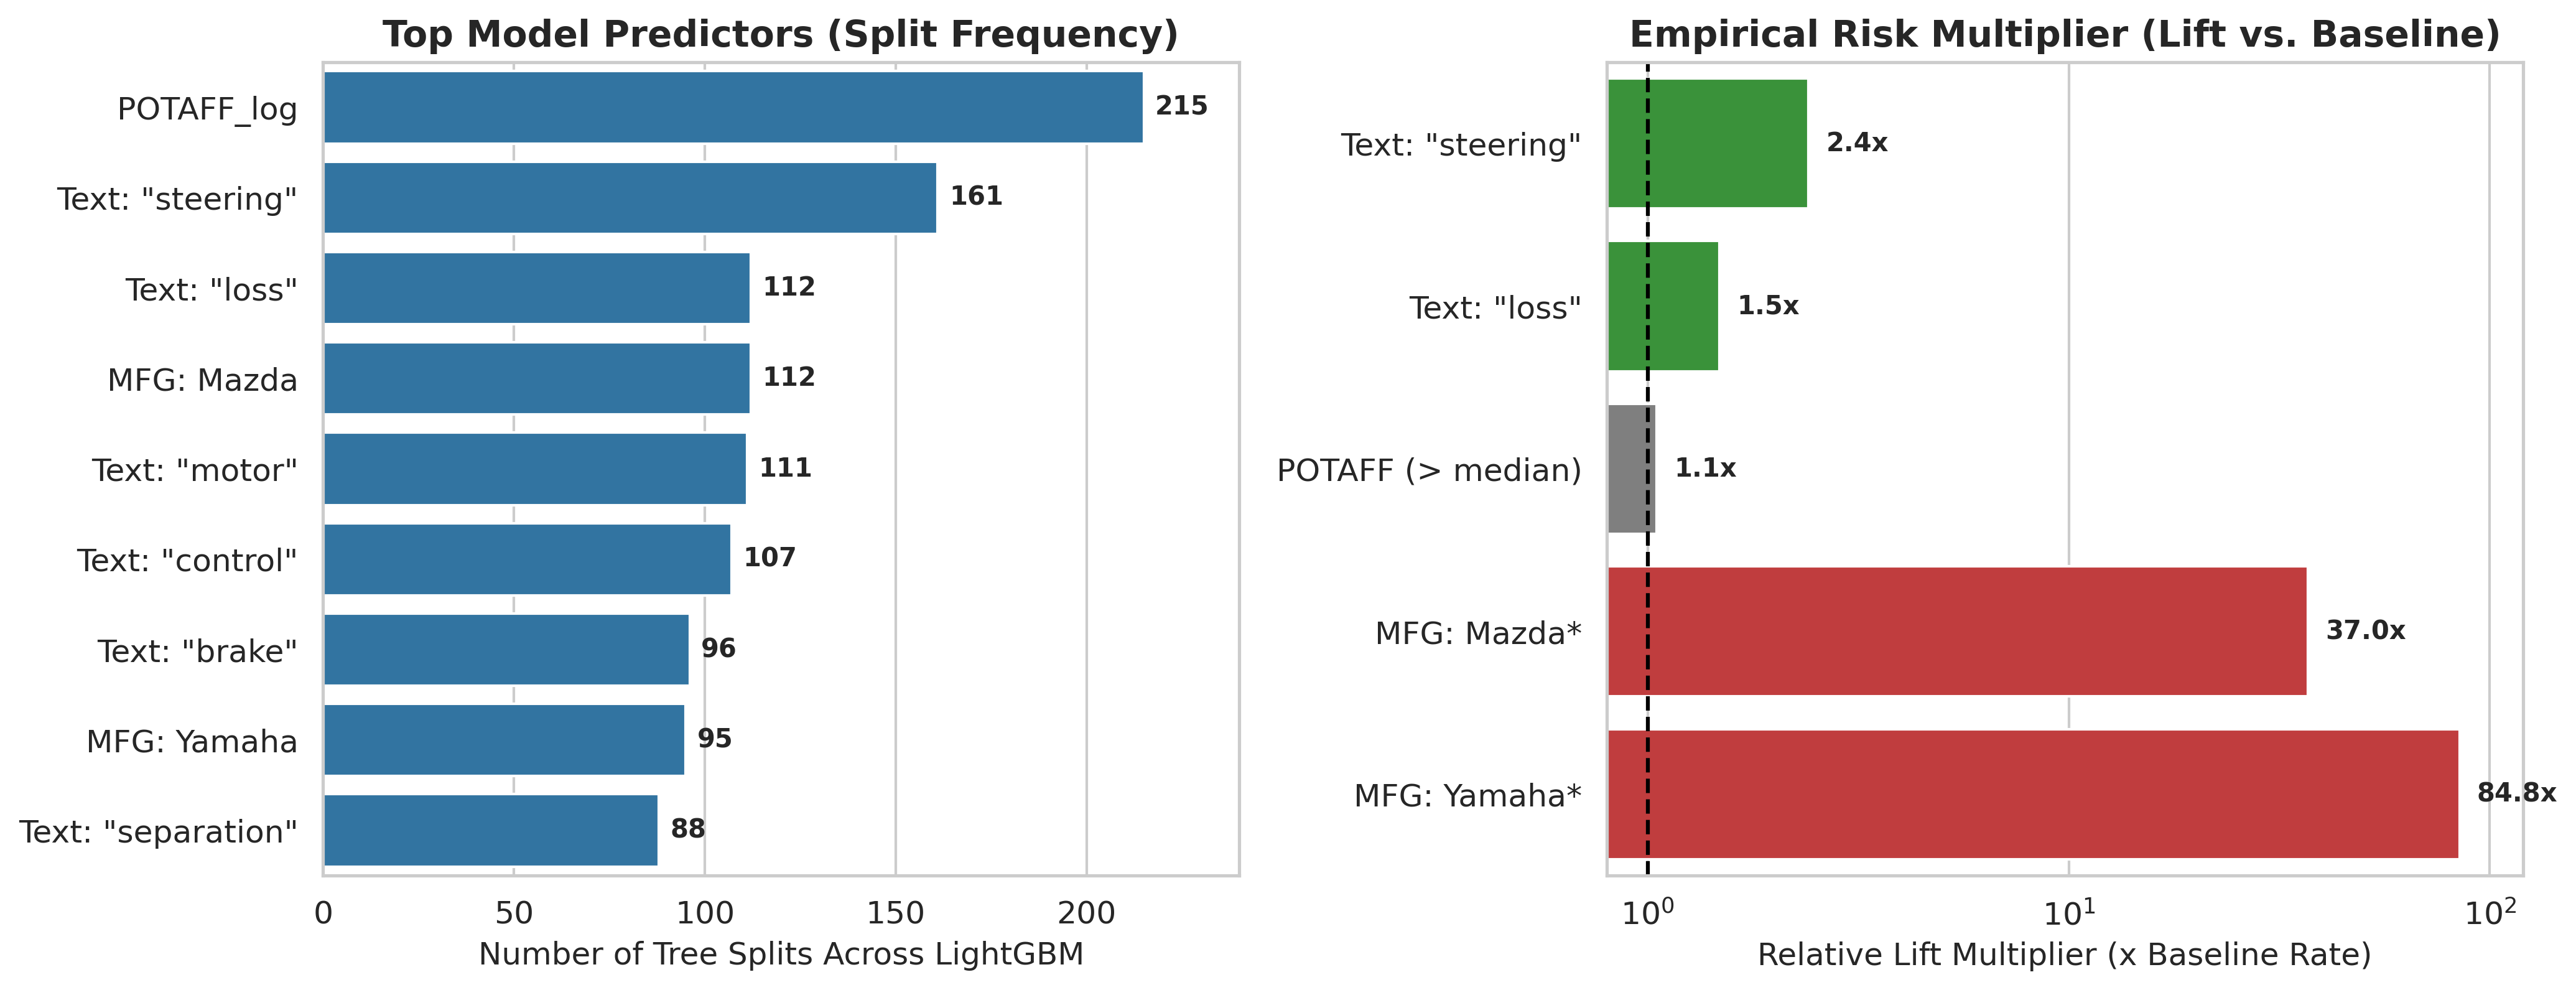

Saved Slide 3 visual to 'slide3_visualizations.png'.


In [46]:
# Visualizations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set clean styling
sns.set_theme(style='whitegrid', font_scale=1.1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=300)

# Panel 1: Top Feature Importance (Splits)
top_features = [
    'POTAFF_log',
    'Text: "steering"',
    'Text: "loss"',
    'MFG: Mazda',
    'Text: "motor"',
    'Text: "control"',
    'Text: "brake"',
    'MFG: Yamaha',
    'Text: "separation"',
]
split_counts = [215, 161, 112, 112, 111, 107, 96, 95, 88]

sns.barplot(x=split_counts, y=top_features, color='#1f77b4', ax=ax1)
ax1.set_title(
    'Top Model Predictors (Split Frequency)', fontsize=14, fontweight='bold'
)
ax1.set_xlabel('Number of Tree Splits Across LightGBM', fontsize=12)
for i, v in enumerate(split_counts):
  ax1.text(v + 3, i, str(v), va='center', fontweight='bold', fontsize=10)
ax1.set_xlim(0, 240)

# Panel 2: Empirical Risk Lift vs Baseline (0.658%)
lift_labels = [
    'Text: "steering"',
    'Text: "loss"',
    'POTAFF (> median)',
    'MFG: Mazda*',
    'MFG: Yamaha*',
]
lift_values = [2.41, 1.48, 1.05, 37.0, 84.8]  # Empirical multipliers
colors = ['#2ca02c', '#2ca02c', '#7f7f7f', '#d62728', '#d62728']

sns.barplot(x=lift_values, y=lift_labels, palette=colors, ax=ax2)
ax2.axvline(
    1.0, color='black', linestyle='--', linewidth=1.5, label='Baseline (1.0x)'
)
ax2.set_title(
    'Empirical Risk Multiplier (Lift vs. Baseline)',
    fontsize=14,
    fontweight='bold',
)
ax2.set_xlabel('Relative Lift Multiplier (x Baseline Rate)', fontsize=12)
ax2.set_xscale('log')  # Log scale to display wide range cleanly
ax2.set_xlim(0.8, 120)
for i, v in enumerate(lift_values):
  ax2.text(v * 1.1, i, f'{v:.1f}x', va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('slide3_visualizations.png', dpi=300, bbox_inches='tight')
plt.show()
print("Saved Slide 3 visual to 'slide3_visualizations.png'.")